# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name: Eshwar Lal**
- **Student ID: 023-24-0186**
- **Section: F**
- **GitHub: https://github.com/Eshwarlal-125/Machine_Learning_Course**
- **Kaggle: https://www.kaggle.com/mreshwar**
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [1]:
# YOUR CODE HERE
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

SEED = 42


### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [2]:
# YOUR CODE HERE
df = pd.read_csv("Mall_Customers.csv")

df.rename(columns={'Annual Income (k$)': 'Income', 'Spending Score (1-100)': 'Spending'}, inplace=True)

print("Shape of dataset: ", df.shape)

print("Missing values: ", df.isnull().sum())

print("Duplicate rows: ", df.duplicated().sum())

print("Gender Count: ", df['Gender'].value_counts())

print(df[['Age','Income','Spending']].describe())

Shape of dataset:  (200, 5)
Missing values:  CustomerID    0
Gender        0
Age           0
Income        0
Spending      0
dtype: int64
Duplicate rows:  0
Gender Count:  Gender
Female    112
Male       88
Name: count, dtype: int64
              Age      Income    Spending
count  200.000000  200.000000  200.000000
mean    38.850000   60.560000   50.200000
std     13.969007   26.264721   25.823522
min     18.000000   15.000000    1.000000
25%     28.750000   41.500000   34.750000
50%     36.000000   61.500000   50.000000
75%     49.000000   78.000000   73.000000
max     70.000000  137.000000   99.000000


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


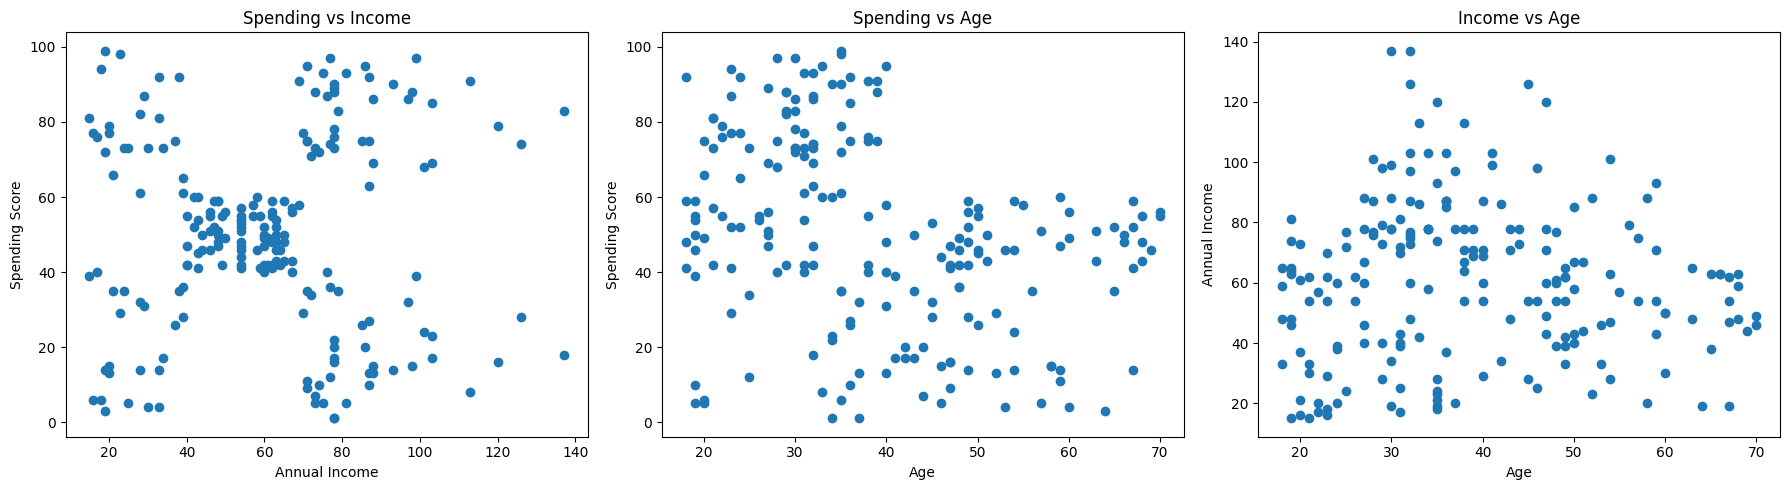

In [3]:
# YOUR CODE HERE
fig, axes = plt.subplots(1,3, figsize=(18,5))

axes[0].scatter(df['Income'], df['Spending'])
axes[0].set_title("Spending vs Income")
axes[0].set_xlabel("Annual Income")
axes[0].set_ylabel("Spending Score")

axes[1].scatter(df['Age'], df['Spending'])
axes[1].set_title("Spending vs Age")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Spending Score")

axes[2].scatter(df['Age'], df['Income'])
axes[2].set_title("Income vs Age")
axes[2].set_xlabel("Age")
axes[2].set_ylabel("Annual Income")

plt.tight_layout()
plt.show()

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



**Your answers:**

(a) First plot shows 5 groups, second plot shows around 2 groups, and third plot does not show clearly defined groups.

(b) We cannot use accuracy because we don't have correct group labels. We only want to discover groups in the data.

(c)

(d)


---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [4]:
# YOUR CODE HERE
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25])

centroids = np.array([4.0, 11.0])
iteration = 0
while True:
    iteration += 1

    distances = np.abs(x[:, None] - centroids[None, :])

    labels = distances.argmin(axis=1)
    
    new_centroids = centroids.copy()
    for k in range(2):
        if np.any(labels == k):
            new_centroids[k] = x[labels == k].mean()

    print("Iteration:", iteration)
    for k in range(2):
        print(f"Cluster C{k+1}:", x[labels == k])

    print("New Centroids:", new_centroids)
    if np.allclose(centroids, new_centroids):
        centroids = new_centroids
        break

    centroids = new_centroids

inertia = np.sum((x - centroids[labels]) ** 2)
print("Final Centroids:", centroids)
print("Final Inertia:", inertia)


Iteration: 1
Cluster C1: [2 4 3]
Cluster C2: [10 12 20 30 11 25]
New Centroids: [ 3. 18.]
Iteration: 2
Cluster C1: [ 2  4 10  3]
Cluster C2: [12 20 30 11 25]
New Centroids: [ 4.75 19.6 ]
Iteration: 3
Cluster C1: [ 2  4 10 12  3 11]
Cluster C2: [20 30 25]
New Centroids: [ 7. 25.]
Iteration: 4
Cluster C1: [ 2  4 10 12  3 11]
Cluster C2: [20 30 25]
New Centroids: [ 7. 25.]
Final Centroids: [ 7. 25.]
Final Inertia: 150.0


### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [5]:
# YOUR CODE HERE
X = np.array([[185, 72], [170, 56], [168, 60], [179, 68], [182, 72], [188, 77]], dtype=float)

centroids = X[[0, 1]].copy()
iteration = 0
while True:
    iteration += 1

    distances = np.sqrt(
        ((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
    )

    labels = distances.argmin(axis=1)

    new_centroids = centroids.copy()
    for k in range(2):
        if np.any(labels == k):
            new_centroids[k] = X[labels == k].mean(axis=0)

    print("Iteration:", iteration)
    for k in range(2):
        print(f"Cluster C{k+1}:")
        print(X[labels == k])

    print("New Centroids: ", new_centroids)
    if np.allclose(centroids, new_centroids):
        centroids = new_centroids
        break
    centroids = new_centroids

distances = np.sqrt(
    ((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
)

print("Final Distance Table:")
print(pd.DataFrame(distances, columns=["Distance to C1", "Distance to C2"],
                   index=["P1", "P2", "P3", "P4", "P5", "P6"]))
print("Final Centroids: ", centroids)


Iteration: 1
Cluster C1:
[[185.  72.]
 [179.  68.]
 [182.  72.]
 [188.  77.]]
Cluster C2:
[[170.  56.]
 [168.  60.]]
New Centroids:  [[183.5   72.25]
 [169.    58.  ]]
Iteration: 2
Cluster C1:
[[185.  72.]
 [179.  68.]
 [182.  72.]
 [188.  77.]]
Cluster C2:
[[170.  56.]
 [168.  60.]]
New Centroids:  [[183.5   72.25]
 [169.    58.  ]]
Final Distance Table:
    Distance to C1  Distance to C2
P1        1.520691       21.260292
P2       21.126109        2.236068
P3       19.756328        2.236068
P4        6.189709       14.142136
P5        1.520691       19.104973
P6        6.543126       26.870058
Final Centroids:  [[183.5   72.25]
 [169.    58.  ]]


### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [10]:
# YOUR CODE HERE

def my_kmeans(X, init_centroids, max_iter=100):
    X = np.array(X, dtype=float)
    centroids = np.array(init_centroids, dtype=float).copy()
    for iteration in range(1, max_iter + 1):
        distances = np.sqrt(
            ((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
        )
        labels = distances.argmin(axis=1)
        new_centroids = centroids.copy()
        for k in range(len(centroids)):
            if np.any(labels == k):
                new_centroids[k] = X[labels == k].mean(axis=0)
        if np.allclose(centroids, new_centroids):
            centroids = new_centroids
            break
        centroids = new_centroids
    distances = np.sqrt(
        ((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
    )
    labels = distances.argmin(axis=1)
    inertia = np.sum((X - centroids[labels]) ** 2)
    return labels, centroids, inertia, iteration


In [11]:
# YOUR CODE HERE
# Example 1
X1 = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25])
# Convert into 2D array
X1 = X1.reshape(-1, 1)
# Initial centroids
initial_centroids = np.array([[4], [11]])
# Call function
labels, centroids, inertia, iterations = my_kmeans(
    X1, initial_centroids
)

print("Labels:", labels)
print("Final Centroids:", centroids.flatten())
print("Inertia:", inertia)
print("Iterations:", iterations)


Labels: [0 0 0 0 0 1 1 0 1]
Final Centroids: [ 7. 25.]
Inertia: 150.0
Iterations: 4


### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [12]:
# YOUR CODE HERE
X2 = df[['Income', 'Spending']].values
initial_centroids = X2[:5].copy()
my_labels, my_centroids, my_inertia, my_iterations = my_kmeans(
    X2, initial_centroids
)
model = KMeans(n_clusters=5, init=initial_centroids, n_init=1, tol=0, algorithm='lloyd')
model.fit(X2)
print("===== MY K-MEANS =====")
print("Iterations:", my_iterations)
print("Inertia:", my_inertia)
print("Centroids:\n", my_centroids)

print("\n===== SCIKIT-LEARN =====")
print("Iterations:", model.n_iter_)
print("Inertia:", model.inertia_)
print("Centroids:\n", model.cluster_centers_)

print("\n===== COMPARISON =====")
print("Labels Match:", np.array_equal(my_labels, model.labels_))
print("Centroids Match:", np.allclose(my_centroids, model.cluster_centers_))
print("Inertia Match:", np.isclose(my_inertia, model.inertia_))


===== MY K-MEANS =====
Iterations: 4
Inertia: 44448.45544793371
Centroids:
 [[26.30434783 20.91304348]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [86.53846154 82.12820513]
 [55.2962963  49.51851852]]

===== SCIKIT-LEARN =====
Iterations: 4
Inertia: 44448.45544793371
Centroids:
 [[26.30434783 20.91304348]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [86.53846154 82.12820513]
 [55.2962963  49.51851852]]

===== COMPARISON =====
Labels Match: True
Centroids Match: True
Inertia Match: True


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



**Your answers:**

(a) Point 10 moved to C1 because the updated C1 centroid became closer to it.

(b) The loop stops when centroids stop changing, it may still reach a local minimum.

(c) Both algorithms produced matching results because we used the same starting centroids.

(d) A centroid represents the average of a cluster. K-means needs numeric features to calculate distances.


---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


    K        Inertia  Silhouette
0   2  181363.595960    0.296897
1   3  106348.373062    0.467614
2   4   73679.789039    0.493196
3   5   44448.455448    0.553932
4   6   37233.814511    0.539761
5   7   30241.343618    0.528810
6   8   25036.417604    0.454812
7   9   21916.794790    0.456109
8  10   20072.070939    0.441057
Best K according to Silhouette: 5


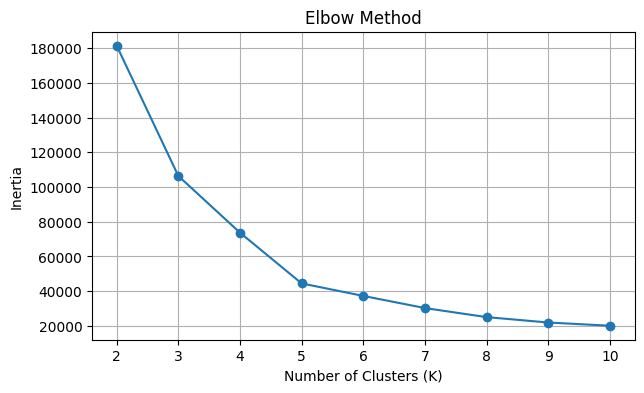

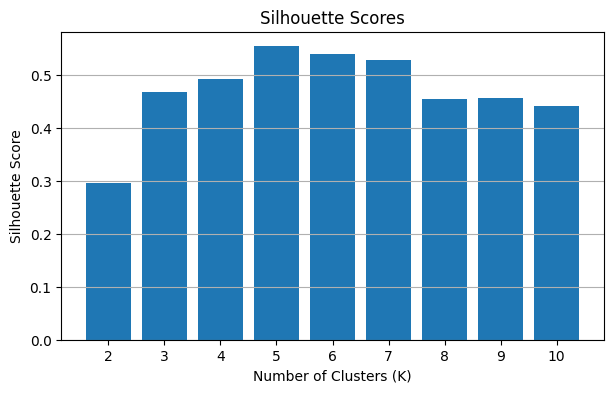

In [16]:
# YOUR CODE HERE
results = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    labels = model.fit_predict(X2)
    inertia = model.inertia_
    silhouette = silhouette_score(X2, labels)
    results.append([k, inertia, silhouette])

results_df = pd.DataFrame(results, columns=['K', 'Inertia', 'Silhouette'])
print(results_df)
best_k = results_df.loc[results_df['Silhouette'].idxmax(), 'K']
print("Best K according to Silhouette:", best_k)

# Elbow Curve
plt.figure(figsize=(7, 4))
plt.plot(results_df['K'], results_df['Inertia'], marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(2, 11))
plt.grid()
plt.show()
# Silhouette Bar Chart
plt.figure(figsize=(7, 4))
plt.bar(results_df['K'], results_df['Silhouette'])
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Scores")
plt.xticks(range(2, 11))
plt.grid(axis='y')
plt.show()


### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [18]:
# YOUR CODE HERE
model5 = KMeans(n_clusters=5, n_init=10, random_state=SEED)
labels5 = model5.fit_predict(X2)
def manual_silhouette(X, labels, i):
    point = X[i]
    distances = np.sqrt(((X - point) ** 2).sum(axis=1))
    same = (labels == labels[i]).copy()
    same[i] = False
    a = distances[same].mean() if same.any() else 0
    b = min(distances[labels == k].mean()
        for k in np.unique(labels)
        if k != labels[i]
    )
    s = (b - a) / max(a, b) if same.any() else 0
    return a, b, s

a, b, s = manual_silhouette(X2, labels5, 0)
sil_values = silhouette_samples(X2, labels5)

print("Customer 1")
print("a =", a)
print("b =", b)
print("Manual Silhouette =", s)
print("Sklearn Silhouette =", sil_values[0])

Customer 1
a = 24.64044215163639
b = 42.26526678748377
Manual Silhouette = 0.41700493041881637
Sklearn Silhouette = 0.4170049304188163



Cluster Silhouette Summary:
         count      mean       min
Cluster                           
0           81  0.596651  0.115294
1           39  0.509171  0.225413
2           22  0.599013  0.050721
3           35  0.503987 -0.023381
4           23  0.512268 -0.009278
Negative Silhouettes: 2


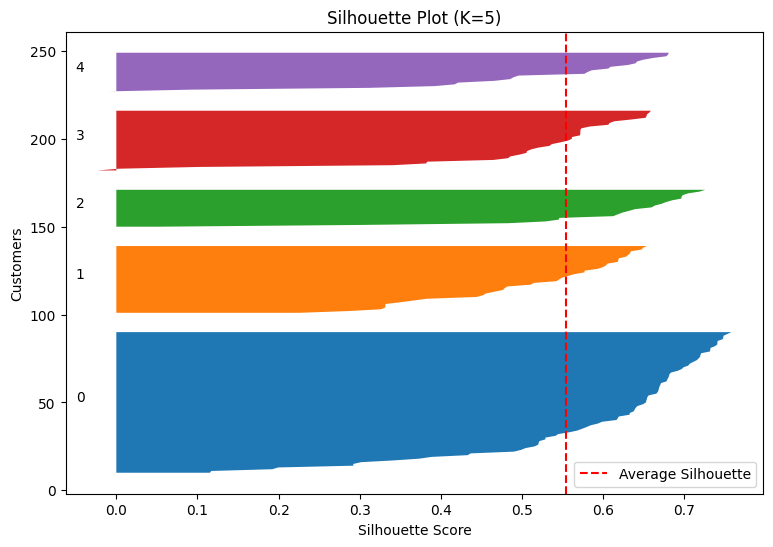

In [ ]:
# YOUR CODE HERE
summary = pd.DataFrame({'Cluster': labels5,'Silhouette': sil_values
}).groupby('Cluster')['Silhouette'].agg(['count', 'mean', 'min'])
print("Cluster Silhouette Summary:")
print(summary)

print("Negative Silhouettes:", np.sum(sil_values < 0))
# Silhouette plot
plt.figure(figsize=(9, 6))
y_lower = 10
for k in range(5):
    values = np.sort(sil_values[labels5 == k])
    size = len(values)
    y_upper = y_lower + size
    plt.fill_betweenx(np.arange(y_lower, y_upper), 0, values)
    plt.text(-0.05, y_lower + size / 2, str(k))
    y_lower = y_upper + 10

plt.axvline(sil_values.mean(), color='red', linestyle='--', label='Average Silhouette')
plt.xlabel("Silhouette Score")
plt.ylabel("Customers")
plt.title("Silhouette Plot (K=5)")
plt.legend()
plt.show()

### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [21]:
# YOUR CODE HERE
X_practice = np.array([1, 3, 5, 7, 11, 13, 15]).reshape(-1, 1)
initial_centroids = np.array([[1], [11]])
labels_practice, centroids_practice, inertia_practice, iterations_practice = my_kmeans(
    X_practice, initial_centroids)
for k in range(2):
    print(f"Cluster C{k+1}:",
          X_practice[labels_practice == k].flatten())
print("Final Centroids:", centroids_practice.flatten())
print("Inertia:", inertia_practice)
print("Iterations:", iterations_practice)

practice_sil = silhouette_samples(X_practice, labels_practice)
for point in [1, 7, 11]:
    index = np.where(X_practice.flatten() == point)[0][0]
    a, b, s = manual_silhouette(X_practice, labels_practice, index)
    print(f"Point: {point}")
    print("a =", a)
    print("b =", b)
    print("Manual Silhouette =", s)
    print("Sklearn Silhouette =", practice_sil[index])


Cluster C1: [1 3 5 7]
Cluster C2: [11 13 15]
Final Centroids: [ 4. 13.]
Inertia: 28.0
Iterations: 3
Point: 1
a = 4.0
b = 12.0
Manual Silhouette = 0.6666666666666666
Sklearn Silhouette = 0.6666666666666666
Point: 7
a = 4.0
b = 6.0
Manual Silhouette = 0.3333333333333333
Sklearn Silhouette = 0.3333333333333333
Point: 11
a = 3.0
b = 7.0
Manual Silhouette = 0.5714285714285714
Sklearn Silhouette = 0.5714285714285714


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



**Your answers:**

(a) Elbow suggests K = 5. Silhouette suggests the K with the highest score.

(b) Higher silhouette means better clustering. Negative scores show poor placement. 

(c) Point 7 is less well placed (0.333) than point 1 (0.667).

(d) Lowest inertia is not always best because it decreases as K increases.


---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


Best Overall Inertia: 44448.45544793371
Experiment Summary:
                      Distinct_Inertias    Lowest   Highest  Best_Inertia_%
Setting                                                                    
K-Means++, n_init=1                   6  44448.46  66733.44           60.00
K-Means++, n_init=10                  1  44448.46  44448.46          100.00
Random, n_init=1                     14  44448.46  91761.98           33.33


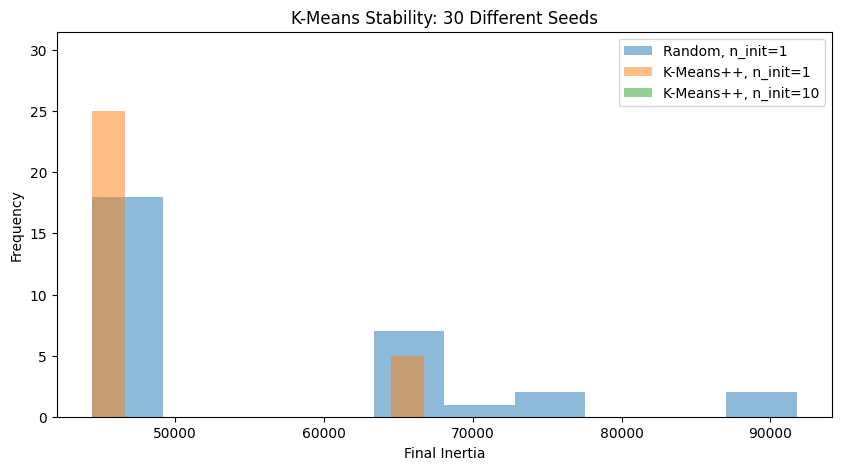

In [24]:
# YOUR CODE HERE
runs = []
settings = [
    ('Random, n_init=1', 'random', 1),
    ('K-Means++, n_init=1', 'k-means++', 1),
    ('K-Means++, n_init=10', 'k-means++', 10)
]
for name, init_method, n in settings:
    for seed in range(30):
        model = KMeans(n_clusters=5, init=init_method, n_init=n, random_state=seed)
        model.fit(X2)
        runs.append({'Setting': name, 'Seed': seed, 'Inertia': model.inertia_})
runs_df = pd.DataFrame(runs)
best_inertia = runs_df['Inertia'].min()
summary = runs_df.groupby('Setting').agg(
    Distinct_Inertias=('Inertia',
                       lambda x: x.round(1).nunique()),
    Lowest=('Inertia', 'min'),
    Highest=('Inertia', 'max')
)
summary['Best_Inertia_%'] = runs_df.groupby('Setting')['Inertia'].apply(
    lambda x: np.isclose(x, best_inertia, rtol=1e-9, atol=1e-6).mean() * 100
)
print("Best Overall Inertia:", best_inertia)
print("Experiment Summary:")
print(summary.round(2))

plt.figure(figsize=(10, 5))
for name, _, _ in settings:
    values = runs_df[runs_df['Setting'] == name]['Inertia']
    plt.hist(values, bins=10, alpha=0.5, label=name)
plt.xlabel("Final Inertia")
plt.ylabel("Frequency")
plt.title("K-Means Stability: 30 Different Seeds")
plt.legend()
plt.show()

### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.


Best Inertia: 44448.45544793371
Worst Inertia: 91761.97619211908
ARI: 0.45525713010305063


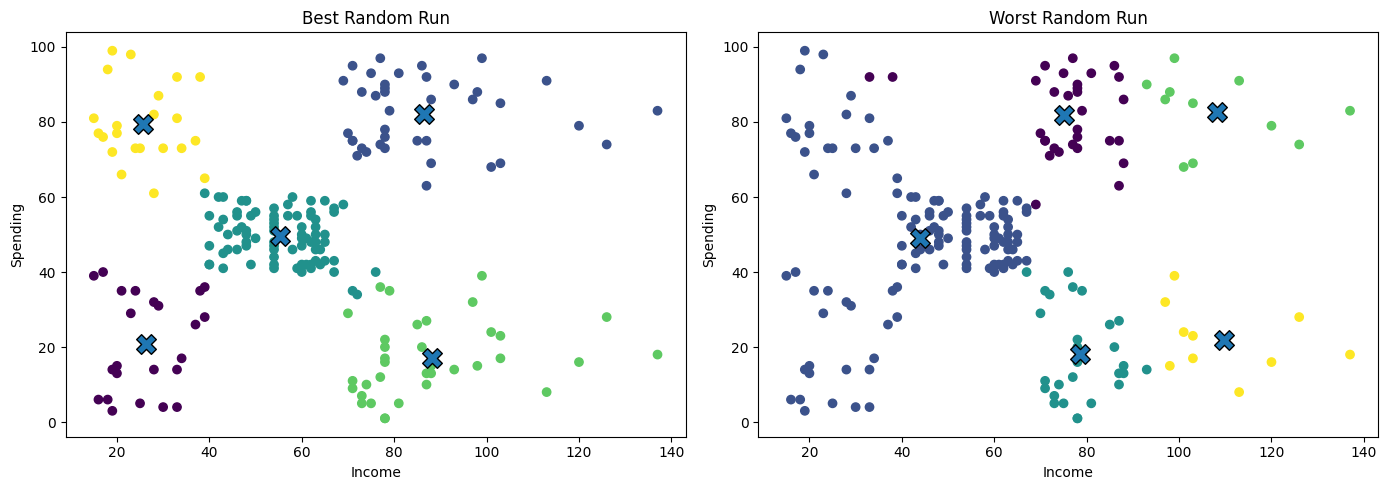

In [25]:
# YOUR CODE HERE
random_runs = runs_df[runs_df['Setting'] == 'Random, n_init=1']
best_seed = random_runs.loc[random_runs['Inertia'].idxmin(), 'Seed']
worst_seed = random_runs.loc[random_runs['Inertia'].idxmax(), 'Seed']
best_model = KMeans(n_clusters=5, init='random', n_init=1, random_state=int(best_seed))
best_labels = best_model.fit_predict(X2)

worst_model = KMeans(n_clusters=5, init='random', n_init=1, random_state=int(worst_seed))
worst_labels = worst_model.fit_predict(X2)
print("Best Inertia:", best_model.inertia_)
print("Worst Inertia:", worst_model.inertia_)
print("ARI:", adjusted_rand_score(best_labels, worst_labels))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(X2[:, 0], X2[:, 1], c=best_labels)
axes[0].scatter(
    best_model.cluster_centers_[:, 0],
    best_model.cluster_centers_[:, 1],
    marker='X', s=200, edgecolors='black'
)
axes[0].set_title("Best Random Run")
axes[1].scatter(X2[:, 0], X2[:, 1], c=worst_labels)
axes[1].scatter(
    worst_model.cluster_centers_[:, 0],
    worst_model.cluster_centers_[:, 1],
    marker='X', s=200, edgecolors='black'
)
axes[1].set_title("Worst Random Run")
for ax in axes:
    ax.set_xlabel("Income")
    ax.set_ylabel("Spending")
plt.tight_layout()
plt.show()

**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?



**Your answers:**

(a) Random initialization produces different inertia values. K-Means++ and n_init=10 give more stable and better results.

(b) Different starting centroids can produce different clusters and lead to different local minima.

(c) K-Means++ selects better starting points, while n_init=10 tries multiple times and keeps the lowest inertia.

(d) ARI compares actual cluster membership, ignoring cluster numbers because cluster labels can be different.


---

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


Raw k$ vs Raw dollars: 0.48965682118947657
Scaled k$ vs Scaled dollars: 1.0
Raw dollars vs Scaled dollars: 0.36045266264603926


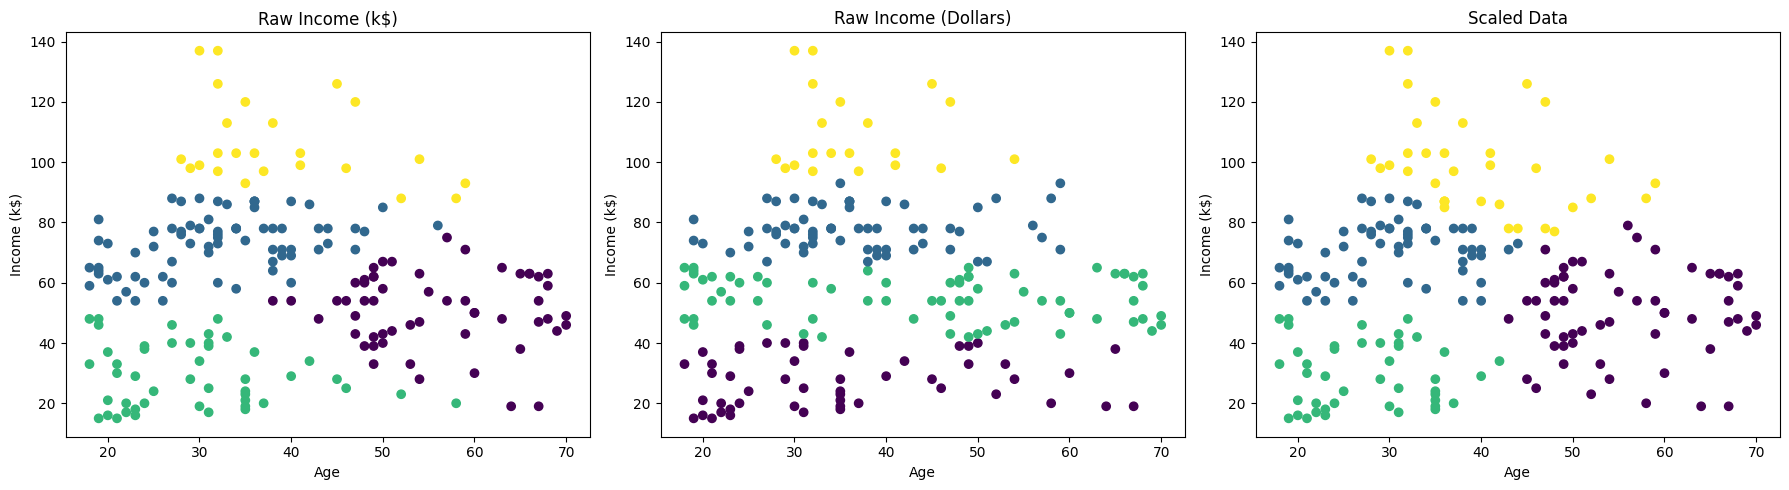

In [26]:
# YOUR CODE HERE
X_raw_ks = df[['Age', 'Income']].values
X_raw_dollars = X_raw_ks.copy()
X_raw_dollars[:, 1] = X_raw_dollars[:, 1] * 1000
scaler1 = StandardScaler()
X_scaled_ks = scaler1.fit_transform(X_raw_ks)
scaler2 = StandardScaler()
X_scaled_dollars = scaler2.fit_transform(X_raw_dollars)
def run_kmeans(X):
    model = KMeans(n_clusters=4, n_init=10, random_state=SEED)
    labels = model.fit_predict(X)
    return labels
labels_raw_ks = run_kmeans(X_raw_ks)
labels_raw_dollars = run_kmeans(X_raw_dollars)
labels_scaled_ks = run_kmeans(X_scaled_ks)
labels_scaled_dollars = run_kmeans(X_scaled_dollars)
print("Raw k$ vs Raw dollars:", adjusted_rand_score(labels_raw_ks, labels_raw_dollars))
print("Scaled k$ vs Scaled dollars:", adjusted_rand_score(labels_scaled_ks, labels_scaled_dollars))
print("Raw dollars vs Scaled dollars:", adjusted_rand_score(labels_raw_dollars, labels_scaled_dollars))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cluster_results = [
    (labels_raw_ks, "Raw Income (k$)"),
    (labels_raw_dollars, "Raw Income (Dollars)"),
    (labels_scaled_ks, "Scaled Data")
]
for ax, (labels, title) in zip(axes, cluster_results):
    ax.scatter(X_raw_ks[:, 0], X_raw_ks[:, 1], c=labels)
    ax.set_title(title)
    ax.set_xlabel("Age")
    ax.set_ylabel("Income (k$)")
plt.tight_layout()
plt.show()

### Task 4.2 — Wine data: raw vs scaled

Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true cultivar is used ONLY to check the result, never to fit K-Means.

1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report ARI against the true cultivar, silhouette score and cluster sizes.


In [27]:
# YOUR CODE HERE
wine = load_wine()
X_wine = wine.data
y_wine = wine.target
wine_df = pd.DataFrame(X_wine, columns=wine.feature_names)

print("Dataset Shape:", X_wine.shape)
print("Number of Cultivars:", len(np.unique(y_wine)))
std_values = wine_df.std()
print("Three Largest Standard Deviations:")
print(std_values.nlargest(3))
print("Smallest Standard Deviation:")
print(std_values.nsmallest(1))

Dataset Shape: (178, 13)
Number of Cultivars: 3
Three Largest Standard Deviations:
proline              314.907474
magnesium             14.282484
alcalinity_of_ash      3.339564
dtype: float64
Smallest Standard Deviation:
nonflavanoid_phenols    0.124453
dtype: float64


In [28]:
# YOUR CODE HERE
scaler = StandardScaler()
X_wine_scaled = scaler.fit_transform(X_wine)
raw_model = KMeans(n_clusters=3, n_init=10, random_state=SEED)
raw_labels = raw_model.fit_predict(X_wine)

scaled_model = KMeans(n_clusters=3, n_init=10, random_state=SEED)
scaled_labels = scaled_model.fit_predict(X_wine_scaled)

print("===== RAW DATA =====")
print("ARI:", adjusted_rand_score(y_wine, raw_labels))
print("Silhouette:", silhouette_score(X_wine, raw_labels))
print("Cluster Sizes:", np.bincount(raw_labels))
print("\n===== SCALED DATA =====")
print("ARI:", adjusted_rand_score(y_wine, scaled_labels))
print("Silhouette:", silhouette_score(X_wine_scaled, scaled_labels))
print("Cluster Sizes:", np.bincount(scaled_labels))



===== RAW DATA =====
ARI: 0.37111371823084754
Silhouette: 0.5711381937868838
Cluster Sizes: [62 47 69]

===== SCALED DATA =====
ARI: 0.8974949815093207
Silhouette: 0.2848589191898987
Cluster Sizes: [65 51 62]


### Task 4.3 — Draw it

Compare the three views in one picture.

1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled clusters.


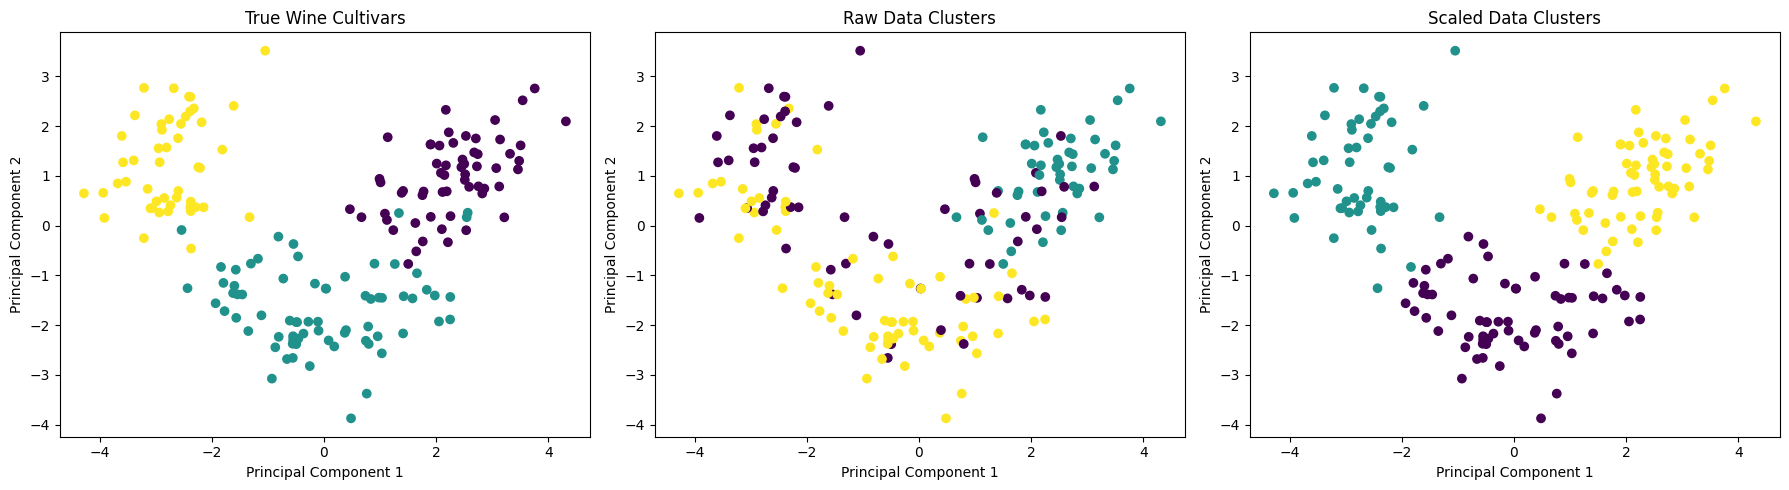

Explained Variance Ratio: [0.36198848 0.1920749 ]
Total Explained Variance: 0.5540633835693526


In [29]:
# YOUR CODE HERE
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_wine_scaled)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y_wine)
axes[0].set_title("True Wine Cultivars")

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=raw_labels)
axes[1].set_title("Raw Data Clusters")
axes[2].scatter(X_pca[:, 0], X_pca[:, 1], c=scaled_labels)
axes[2].set_title("Scaled Data Clusters")
for ax in axes:
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Explained Variance:", pca.explained_variance_ratio_.sum())


**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).

(b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.

(d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.



**Your answers:**

(a) After changing Income to dollars, Income dominated the distance because its values became much larger than Age. So, K-Means focused more on Income.

(b)  Proline dominated the raw Wine data. Its standard deviation was much higher than the other features. ARI was better on scaled data than raw data.

(c) Silhouette measures how well-separated clusters are, not whether they match the real cultivars. Raw and scaled data use different distance scales, so their scores are not directly comparable.

(d) I would scale the data when features have very different ranges. Then I would compare clustering results to choose the better approach.


---

## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.


In [30]:
# YOUR CODE HERE
extra_customer = np.array([[400, 99]])
X_original = X2.copy()
X_with_outlier = np.vstack([X_original, extra_customer])
model_original = KMeans(n_clusters=5, n_init=10, random_state=SEED)
labels_original = model_original.fit_predict(X_original)

model_outlier = KMeans(n_clusters=5, n_init=10, random_state=SEED)
labels_outlier = model_outlier.fit_predict(X_with_outlier)
original_centroids = model_original.cluster_centers_
outlier_centroids = model_outlier.cluster_centers_
original_centroids = original_centroids[np.argsort(original_centroids[:, 0])]
outlier_centroids = outlier_centroids[np.argsort(outlier_centroids[:, 0])]

print("Original Cluster Sizes:")
print(np.bincount(labels_original))
print("Cluster Sizes With Outlier:")
print(np.bincount(labels_outlier))
print("Original Centroids (Income, Spending):")
print(original_centroids)
print("Centroids With Outlier:")
print(outlier_centroids)

ari = adjusted_rand_score(labels_original, labels_outlier[:200])
print("ARI between original clusterings:", ari)

Original Cluster Sizes:
[81 39 22 35 23]
Cluster Sizes With Outlier:
[100   1  23  39  38]
Original Centroids (Income, Spending):
[[25.72727273 79.36363636]
 [26.30434783 20.91304348]
 [55.2962963  49.51851852]
 [86.53846154 82.12820513]
 [88.2        17.11428571]]
Centroids With Outlier:
[[ 26.30434783  20.91304348]
 [ 48.26        56.48      ]
 [ 86.53846154  82.12820513]
 [ 87.          18.63157895]
 [400.          99.        ]]
ARI between original clusterings: 0.7532040415286123


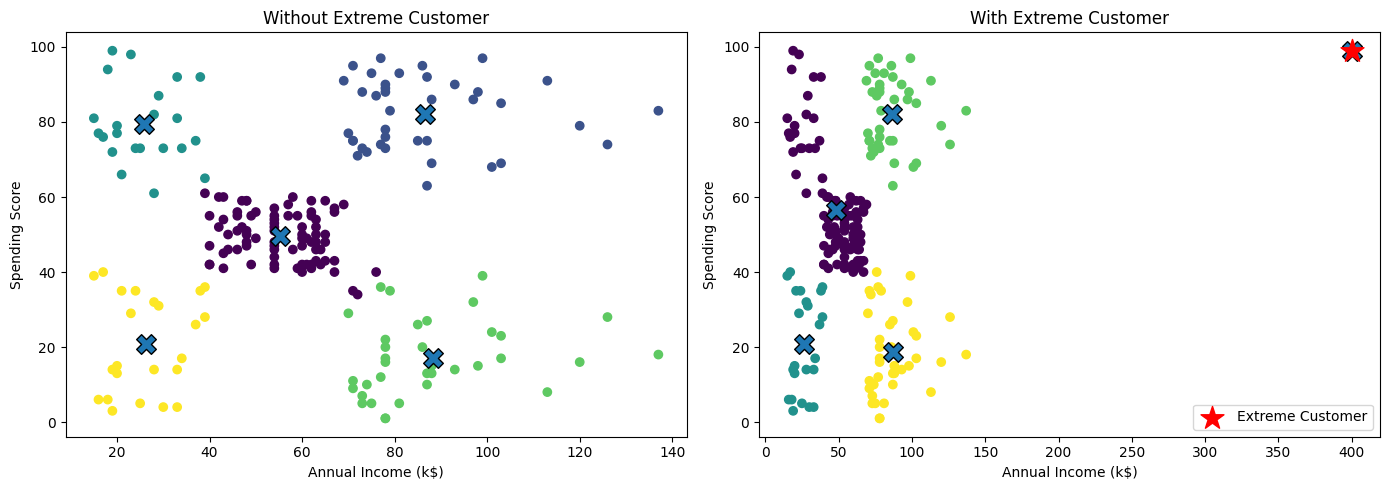

In [31]:
# YOUR CODE HERE
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(X_original[:, 0], X_original[:, 1], c=labels_original)
axes[0].scatter(model_original.cluster_centers_[:, 0],
    model_original.cluster_centers_[:, 1],
    marker='X',
    s=200,
    edgecolors='black'
)
axes[0].set_title("Without Extreme Customer")
axes[1].scatter(X_with_outlier[:, 0], X_with_outlier[:, 1], c=labels_outlier)
axes[1].scatter(model_outlier.cluster_centers_[:, 0],
    model_outlier.cluster_centers_[:, 1],
    marker='X',
    s=200,
    edgecolors='black'
)
axes[1].scatter(400, 99, marker='*', s=300, color='red', label='Extreme Customer')
axes[1].set_title("With Extreme Customer")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score")
plt.tight_layout()
plt.show()

### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


In [32]:
# YOUR CODE HERE
real_distances = model_original.transform(X_original).min(axis=1)
extra_distance = model_original.transform(extra_customer).min()
mean_dist = real_distances.mean()
std_dist = real_distances.std(ddof=1)
threshold = mean_dist + 3 * std_dist
flagged = real_distances > threshold
extra_flagged = extra_distance > threshold
print("Mean Distance:", mean_dist)
print("Standard Deviation:", std_dist)
print("Threshold:", threshold)
print("Flagged Real Customers:", flagged.sum())
print("Extra Customer Distance:", extra_distance)
print("Is Extra Customer Flagged?", extra_flagged)

result = df[['CustomerID', 'Age', 'Income', 'Spending']].copy()
result['Cluster'] = labels_original
result['Distance'] = real_distances
print("\nFive Farthest Customers:")
print(result.nlargest(5, 'Distance').to_string(index=False))
X_clean = X_original[~flagged]
repaired_model = KMeans(n_clusters=5,n_init=10,random_state=SEED)
repaired_model.fit(X_clean)

repaired_labels = repaired_model.predict(X_original)

ari_repaired = adjusted_rand_score(labels_original, repaired_labels)
print("===== REPAIRED MODEL =====")
print("Remaining Customers:", len(X_clean))
print("New Cluster Sizes:", np.bincount(repaired_model.labels_))
print("ARI against Original Model:", ari_repaired)

Mean Distance: 13.020126350791761
Standard Deviation: 7.278976890466592
Threshold: 34.85705702219154
Flagged Real Customers: 4
Extra Customer Distance: 313.9152649312717
Is Extra Customer Flagged? True

Five Farthest Customers:
 CustomerID  Age  Income  Spending  Cluster  Distance
        200   30     137        83        1 50.469069
        199   32     137        18        3 48.808037
        198   32     126        74        1 40.289958
        197   45     126        28        3 39.336227
        196   35     120        79        1 33.607443
===== REPAIRED MODEL =====
Remaining Customers: 196
New Cluster Sizes: [80 34 23 37 22]
ARI against Original Model: 0.9847169139719528


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.

(c) Name two ways to deal with outliers and one risk of simply deleting them.



**Your answers:**

(a) The extreme customer pulled a centroid towards high income. This affected the high-income customer groups and changed their cluster sizes.

(b) The rule detected the extra customer but also flagged some real customers. They may be unusual customers, not necessarily data errors.

(c) Two ways are removing outliers or limiting their extreme values. Deleting them may remove important real information.

(d)


---

## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [33]:
# YOUR CODE HERE
df_profile = df.copy()
df_profile['Cluster'] = labels5
profile = df_profile.groupby('Cluster').agg(
    Customers=('CustomerID', 'count'),
    Mean_Age=('Age', 'mean'),
    Mean_Income=('Income', 'mean'),
    Mean_Spending=('Spending', 'mean'),
    Female_Percentage=('Gender',
                       lambda x: (x == 'Female').mean() * 100)
).reset_index()

profile = profile.sort_values('Mean_Income')
print("Customer Cluster Profiles:")
print(profile.round(2).to_string(index=False))

Customer Cluster Profiles:
 Cluster  Customers  Mean_Age  Mean_Income  Mean_Spending  Female_Percentage
       2         22     25.27        25.73          79.36              59.09
       4         23     45.22        26.30          20.91              60.87
       0         81     42.72        55.30          49.52              59.26
       1         39     32.69        86.54          82.13              53.85
       3         35     41.11        88.20          17.11              45.71


In [34]:
# YOUR CODE HERE
def income_category(value):
    if value < 40:
        return "Low Income"
    elif value >= 70:
        return "High Income"
    else:
        return "Mid Income"

def spending_category(value):
    if value < 35:
        return "Low Spending"
    elif value >= 65:
        return "High Spending"
    else:
        return "Mid Spending"

df_profile['Segment'] = (
    df_profile['Income'].apply(income_category)
    + " - "
    + df_profile['Spending'].apply(spending_category)
)

segment_sizes = df_profile['Segment'].value_counts()
print("Customer Segment Sizes:")
print(segment_sizes)

Customer Segment Sizes:
Segment
Mid Income - Mid Spending      77
High Income - High Spending    37
High Income - Low Spending     33
Low Income - High Spending     21
Low Income - Low Spending      17
Low Income - Mid Spending       8
High Income - Mid Spending      6
Mid Income - High Spending      1
Name: count, dtype: int64


### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [35]:
# YOUR CODE HERE
gender_analysis = df_profile.groupby('Segment').agg(
    Customers=('Gender', 'count'),
    Female_Percentage=('Gender',
                       lambda x: (x == 'Female').mean() * 100)
)
print("Women in Each Segment:")
print(gender_analysis.round(2))

overall_female = (df['Gender'] == 'Female').mean() * 100
print("Overall Female Percentage:", round(overall_female, 2), "%")

X3 = df[['Age', 'Income', 'Spending']].values
scaler3 = StandardScaler()
X3_scaled = scaler3.fit_transform(X3)
silhouette_results = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    labels = model.fit_predict(X3_scaled)
    score = silhouette_score(X3_scaled, labels)
    silhouette_results.append([k, score])
silhouette_df = pd.DataFrame(silhouette_results, columns=['K', 'Silhouette'])
print("Silhouette Scores:")
print(silhouette_df.round(4))
best_k_3 = int(silhouette_df.loc[silhouette_df['Silhouette'].idxmax(), 'K'])
print("Best K:", best_k_3)

Women in Each Segment:
                             Customers  Female_Percentage
Segment                                                  
High Income - High Spending         37              56.76
High Income - Low Spending          33              45.45
High Income - Mid Spending           6              50.00
Low Income - High Spending          21              61.90
Low Income - Low Spending           17              64.71
Low Income - Mid Spending            8              50.00
Mid Income - High Spending           1               0.00
Mid Income - Mid Spending           77              58.44
Overall Female Percentage: 56.0 %
Silhouette Scores:
   K  Silhouette
0  2      0.3355
1  3      0.3578
2  4      0.4040
3  5      0.4166
4  6      0.4284
5  7      0.4172
6  8      0.4082
Best K: 6


### Task 6.3 — A three-feature alternative

Cluster the scaled Age, Income and Spending with the best K from the table above.

1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.


In [36]:
# YOUR CODE HERE
model3 = KMeans(n_clusters=best_k_3, n_init=10, random_state=SEED)
labels3 = model3.fit_predict(X3_scaled)
df_three = df.copy()
df_three['Cluster'] = labels3
profile3 = df_three.groupby('Cluster').agg(
    Size=('CustomerID', 'count'),
    Age=('Age', 'mean'),
    Income=('Income', 'mean'),
    Spending=('Spending', 'mean')
).reset_index()
profile3 = profile3.sort_values('Age')
print("Three-Feature Cluster Profile:")
print(profile3.round(2).to_string(index=False))
ari = adjusted_rand_score(labels5, labels3)
print("ARI (Three Features vs Two Features):", ari)

Three-Feature Cluster Profile:
 Cluster  Size   Age  Income  Spending
       4    23 25.00   25.26     77.61
       1    39 26.79   57.10     48.13
       3    39 32.69   86.54     82.13
       2    33 41.94   88.94     16.97
       5    21 45.52   26.29     19.38
       0    45 56.33   54.27     49.07
ARI (Three Features vs Two Features): 0.7002329184122666


**Questions** (answer with your own numbers)

(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?

(c) Does Gender help to separate the segments? Quote the percentages.

(d) Does adding Age change the story? Which segmentation would you present and why? (Careful: silhouette values from different feature sets are not directly comparable.)



**Your answers:**

(a) 
1. High Income, High Spending – Offer premium rewards.
2. High Income, Low Spending – Give special discounts.
3. Mid Income, Mid Spending – Offer loyalty points.
4. Low Income, High Spending – Give exclusive deals.
5. Low Income, Low Spending – Offer budget-friendly products.

(b) High Income, High Spending customers are most valuable. High Income, Low Spending customers are the biggest opportunity because they can be encouraged to spend more.

(c) Gender does not strongly separate the segments if female percentages are similar across groups.

(d) Adding Age may change the customer groups. I would present the segmentation that gives clearer and more useful business insights.


---

## Part 7 — Final Output and Wrap-Up (15 minutes)

Package your result like you would give it to a marketing team.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |


### Task 7.1 — Save the segments

Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.

1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


In [37]:
# YOUR CODE HERE
final_data = df_profile[
    ['CustomerID', 'Age', 'Gender', 'Income',
     'Spending', 'Cluster', 'Segment']
].copy()
final_data.to_csv('customer_segments.csv', index=False)

print("Customer Segments Saved Successfully!")
print(final_data.head())
print("Customers Per Segment:")
print(final_data['Segment'].value_counts())
print("Total Customers:", len(final_data))

Customer Segments Saved Successfully!
   CustomerID  Age  Gender  Income  Spending  Cluster  \
0           1   19    Male      15        39        4   
1           2   21    Male      15        81        2   
2           3   20  Female      16         6        4   
3           4   23  Female      16        77        2   
4           5   31  Female      17        40        4   

                      Segment  
0   Low Income - Mid Spending  
1  Low Income - High Spending  
2   Low Income - Low Spending  
3  Low Income - High Spending  
4   Low Income - Mid Spending  
Customers Per Segment:
Segment
Mid Income - Mid Spending      77
High Income - High Spending    37
High Income - Low Spending     33
Low Income - High Spending     21
Low Income - Low Spending      17
Low Income - Mid Spending       8
High Income - Mid Spending      6
Mid Income - High Spending      1
Name: count, dtype: int64
Total Customers: 200


**Executive Summary** (6-8 lines)
1. I selected K = 5 to divide customers into five groups.
2. I used the Elbow Method and Silhouette Score to evaluate K.
3. The five segments represent different income and spending levels.
4. Premium customers will receive special rewards and offers.
5. Potential customers will receive discounts to increase spending.
6. I used scaling to prevent large values from dominating clustering.
7. I checked outliers using the mean + 3 standard deviations rule.
8. One limitation is that customer behaviour may change over time.



**Questions** (answer with your own numbers)

(a) What was the most surprising result in this lab?

(b) If you had one more hour, what would you try next?



**Your answers:**

(a) The most surprising result was that one extreme customer could change the K-Means clusters significantly.

(b) I would try different values of K and compare the results to find better customer groups.

(c)

(d)


---